# 3. Distribución y evolución de la demanda

Se examinan el nivel, la dispersión y el crecimiento temporal de la demanda. Las estadísticas agregadas se calculan sobre observaciones horarias.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


count    192864.000000
mean          6.527542
std           1.526444
min           0.413149
1%            3.443952
5%            4.058959
50%           6.488990
95%           9.065603
99%           9.661139
max          10.886376
Name: y_demanda_real_kwh, dtype: float64

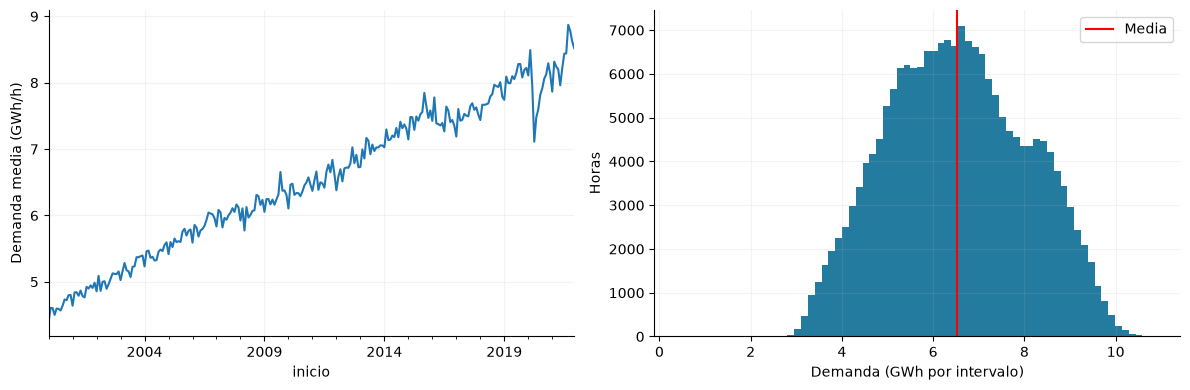

In [2]:
resumen=gwh.describe(percentiles=[.01,.05,.5,.95,.99]); display(resumen); media=float(gwh.mean()); mediana=float(gwh.median()); asimetria=float(gwh.skew()); anual=gwh.groupby(gwh.index.year).agg(['mean','median','std','min','max']); inicial=float(anual['mean'].iloc[0]); final=float(anual['mean'].iloc[-1]); crecimiento=100*(final/inicial-1)
fig,axes=plt.subplots(1,2,figsize=(12,4)); gwh.resample('MS').mean().plot(ax=axes[0]); axes[0].set_ylabel('Demanda media (GWh/h)'); axes[1].hist(gwh,bins=70,color='#247ba0'); axes[1].axvline(media,color='r',label='Media'); axes[1].set_xlabel('Demanda (GWh por intervalo)'); axes[1].set_ylabel('Horas'); axes[1].legend(); fig.tight_layout(); display(fig); plt.close(fig)

La demanda media anual pasa de 4.63 a 8.37 GWh por intervalo entre los extremos del desarrollo, un cambio del 80.8 %. La media global es 6.53 y la mediana 6.49; la distribución reúne años con distintos niveles, por lo que no describe un régimen único.

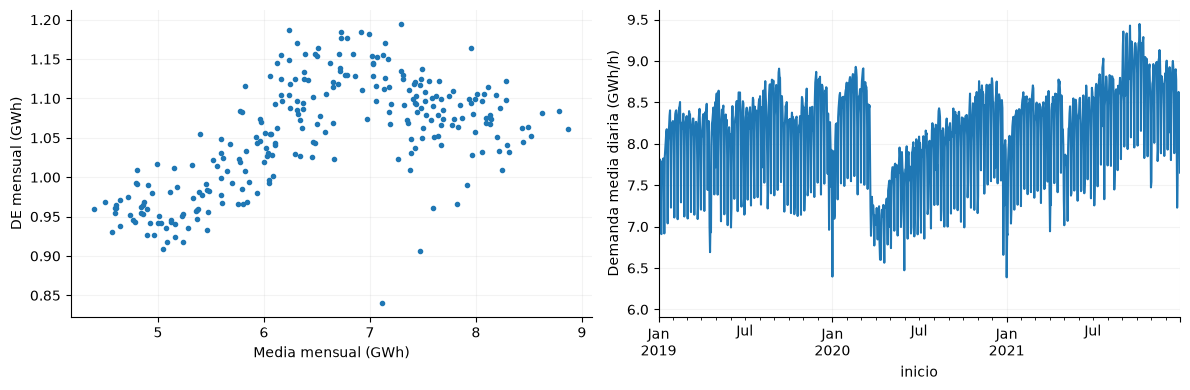

In [3]:
mensual=gwh.resample('MS').agg(['mean','std']); fig,axes=plt.subplots(1,2,figsize=(12,4)); axes[0].plot(mensual['mean'],mensual['std'],'.'); axes[0].set(xlabel='Media mensual (GWh)',ylabel='DE mensual (GWh)'); gwh.resample('D').mean().loc['2019':'2021'].plot(ax=axes[1]); axes[1].set_ylabel('Demanda media diaria (GWh/h)'); correlacion_nivel=float(mensual['mean'].corr(mensual['std'])); fig.tight_layout(); display(fig); plt.close(fig)

La asociación entre nivel y dispersión mensual es 0.59. La ventana 2019–2021 permite distinguir cambios locales que el agregado de todo el histórico comprime; la comparación de errores absolutos entre regímenes debe considerar la escala de la demanda.

## Cambios exploratorios de régimen

Se calcula el logaritmo de la demanda diaria y se retira el perfil medio de día de semana estimado en 2000–2017. Sobre la serie resultante se aplica segmentación binaria por reducción de suma de cuadrados, con segmentos mínimos de 180 días, candidatos semanales, penalización de tres veces el logaritmo del tamaño de muestra y un máximo de seis cortes. Es un diagnóstico retrospectivo de nivel; la tendencia puede generar cortes sin una ruptura abrupta y las fechas no se utilizan como entradas del pronóstico.

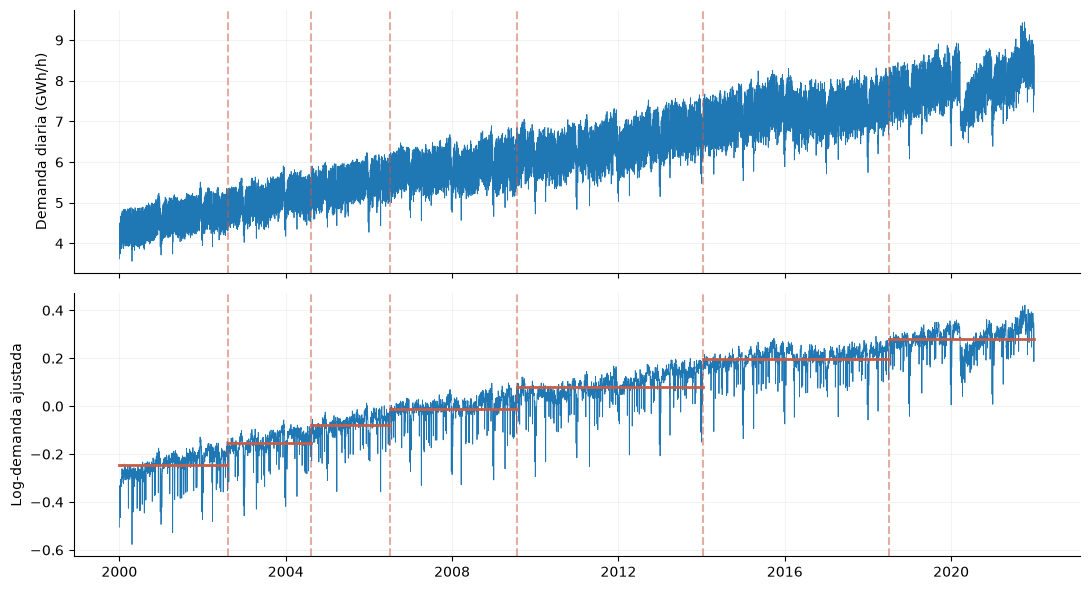

In [4]:
diaria_reg=gwh.resample('D').mean()
log_diaria=np.log(diaria_reg)
base=log_diaria.loc[log_diaria.index<'2018-01-01']
perfil_semana=base.groupby(base.index.day_of_week).mean()
ajustada=log_diaria-pd.Series(log_diaria.index.day_of_week,index=log_diaria.index).map(perfil_semana)
v=((ajustada-ajustada.mean())/ajustada.std()).to_numpy()
cs=np.r_[0,np.cumsum(v)]; cs2=np.r_[0,np.cumsum(v*v)]
def sse(a,b):
    return cs2[b]-cs2[a]-(cs[b]-cs[a])**2/(b-a)
segmentos=[(0,len(v))]; cortes=[]; minimo=180; umbral=3*np.log(len(v))
for _ in range(6):
    opciones=[]
    for a,b in segmentos:
        for k in range(a+minimo,b-minimo+1,7):
            opciones.append((sse(a,b)-sse(a,k)-sse(k,b),a,b,k))
    if not opciones: break
    ganancia,a,b,k=max(opciones)
    if ganancia<=umbral: break
    cortes.append(k); segmentos.remove((a,b)); segmentos.extend([(a,k),(k,b)])
fechas_corte=diaria_reg.index[sorted(cortes)]
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].plot(diaria_reg.index,diaria_reg,lw=.6); axes[0].set_ylabel('Demanda diaria (GWh/h)')
axes[1].plot(ajustada.index,ajustada,lw=.6); axes[1].set_ylabel('Log-demanda ajustada')
for a,b in sorted(segmentos):
    axes[1].plot([ajustada.index[a],ajustada.index[b-1]],[ajustada.iloc[a:b].mean()]*2,color='#c65d47',lw=2)
for fecha in fechas_corte:
    for ax in axes: ax.axvline(fecha,color='#c65d47',ls='--',alpha=.5)
fig.tight_layout(); display(fig); plt.close(fig)
n_cortes=len(cortes); fechas_texto=', '.join(f.strftime('%Y-%m-%d') for f in fechas_corte) or 'ninguna'


El procedimiento identifica 6 cortes: 2002-08-08, 2004-08-12, 2006-07-04, 2009-07-23, 2014-01-14, 2018-07-08. Los tramos resumen cambios de nivel de la demanda ajustada por día de semana, sin atribuirlos a causas económicas o sanitarias. La comparación anual y la normalización por nivel permiten evaluar estos regímenes sin convertir los cortes retrospectivos en información disponible al origen.

**Decisión.** Examinar la normalización por el nivel de la ventana histórica.

**Impacto.** Reduce la influencia del crecimiento sobre la representación de entradas y errores.

**Riesgo.** Una escala calculada con observaciones futuras produciría fuga temporal.